In [1]:
pip install tensorflow-datasets

Note: you may need to restart the kernel to use updated packages.


In [1]:
import tensorflow as tf
import tensorflow_datasets as tfds
import numpy as np

print(tf.__version__)
print(tfds.__version__)

I0000 00:00:1794264471.011080   48074 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1794264471.011583   48074 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
I0000 00:00:1794264471.039274   48074 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX512F AVX512_VNNI FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
I0000 00:00:1794264472.298445   48074 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.

2.22.0-rc0
4.9.10


In [2]:
datos, metadatos = tfds.load('fashion_mnist', as_supervised=True, with_info=True)

E0000 00:00:1794264473.667737   48074 cuda_platform.cc:57] failed call to cuInit: INTERNAL: CUDA error: Failed call to cuInit: UNKNOWN ERROR (303)
=== Source Location Trace: === 
external/xla/xla/stream_executor/cuda/cuda_status.cc:50



In [3]:
print(metadatos)

tfds.core.DatasetInfo(
    name='fashion_mnist',
    full_name='fashion_mnist/3.0.1',
    description="""
    Fashion-MNIST is a dataset of Zalando's article images consisting of a training set of 60,000 examples and a test set of 10,000 examples. Each example is a 28x28 grayscale image, associated with a label from 10 classes.
    """,
    homepage='https://github.com/zalandoresearch/fashion-mnist',
    data_dir='/home/alexi-dg/tensorflow_datasets/fashion_mnist/3.0.1',
    file_format=tfrecord,
    download_size=29.45 MiB,
    dataset_size=36.42 MiB,
    features=FeaturesDict({
        'image': Image(shape=(28, 28, 1), dtype=uint8),
        'label': ClassLabel(shape=(), dtype=int64, num_classes=10),
    }),
    supervised_keys=('image', 'label'),
    disable_shuffling=False,
    nondeterministic_order=False,
    splits={
        'test': <SplitInfo num_examples=10000, num_shards=1>,
        'train': <SplitInfo num_examples=60000, num_shards=1>,
    },
    citation="""@article{DBLP:jour

In [4]:
print("Entrenamiento:", metadatos.splits['train'].num_examples)
print("Pruebas:", metadatos.splits['test'].num_examples)
print("Clases:", metadatos.features['label'].num_classes)

Entrenamiento: 60000
Pruebas: 10000
Clases: 10


In [5]:
datos_entrenamiento, datos_prueba = datos['train'], datos['test']

In [6]:
nombres_clases = metadatos.features['label'].names

In [7]:
nombres_clases

['T-shirt/top',
 'Trouser',
 'Pullover',
 'Dress',
 'Coat',
 'Sandal',
 'Shirt',
 'Sneaker',
 'Bag',
 'Ankle boot']

In [8]:
# Normalización de datos
def normalizar(imagenes, etiquetas):
    imagenes = tf.cast(imagenes, tf.float32)
    imagenes /= 255 #Aqui lo pasa de 0-255 a 0-1
    return imagenes, etiquetas

# Normalizar los datos de entrenamiento y pruebas con la funcion anterior
datos_entrenamiento = datos_entrenamiento.map(normalizar)
datos_prueba = datos_prueba.map(normalizar)

# Agregar datos a caché(usa memoria en lugar de disco, entrenamiento más rapido)
datos_entrenamiento = datos_entrenamiento.cache()
datos_prueba = datos_prueba.cache()

I0000 00:00:1794264486.989444   48219 tf_record_dataset_op.cc:398] The default buffer size is 262144, which is overridden by the user specified `buffer_size` of 8388608
W0000 00:00:1794264486.993565   48225 cache_dataset_ops.cc:956] The calling iterator did not fully read the dataset being cached. In order to avoid unexpected truncation of the dataset, the partially cached contents of the dataset will be discarded. This can happen if you have an input pipeline similar to `dataset.cache().take(k).repeat()`, or if downstream operations drop elements (e.g. `batch(drop_remainder=True)`). You should use `dataset.take(k).cache().repeat()` instead, or ensure the dataset size is a multiple of the batch size before caching. Another common workaround is to place the `.cache()` operation after the operation that drops elements (like `.batch(...)`), if caching the transformed data is acceptable.
W0000 00:00:1794264486.993641   48225 cache_dataset_ops.cc:956] The calling iterator did not fully read

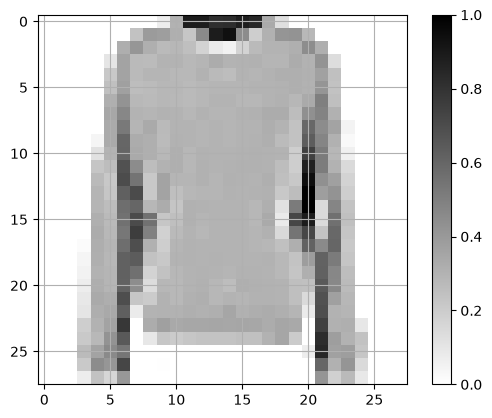

In [9]:
# Mostrar imagen de los datos de prueba, de momento mostramos al primera
for imagen, etiqueta in datos_entrenamiento.take(1):
    break

imagen = imagen.numpy().reshape((28,28)) # Redimensionar, cosas de tensores, se verá despues.

import matplotlib.pyplot as plt

# Dibujar dibujar
plt.figure()
plt.imshow(imagen, cmap=plt.cm.binary)
plt.colorbar()
plt.grid(True)
plt.show()

W0000 00:00:1794264488.119014   48301 cache_dataset_ops.cc:956] The calling iterator did not fully read the dataset being cached. In order to avoid unexpected truncation of the dataset, the partially cached contents of the dataset will be discarded. This can happen if you have an input pipeline similar to `dataset.cache().take(k).repeat()`, or if downstream operations drop elements (e.g. `batch(drop_remainder=True)`). You should use `dataset.take(k).cache().repeat()` instead, or ensure the dataset size is a multiple of the batch size before caching. Another common workaround is to place the `.cache()` operation after the operation that drops elements (like `.batch(...)`), if caching the transformed data is acceptable.
W0000 00:00:1794264488.119124   48301 cache_dataset_ops.cc:956] The calling iterator did not fully read the dataset being cached. In order to avoid unexpected truncation of the dataset, the partially cached contents of the dataset will be discarded. This can happen if you

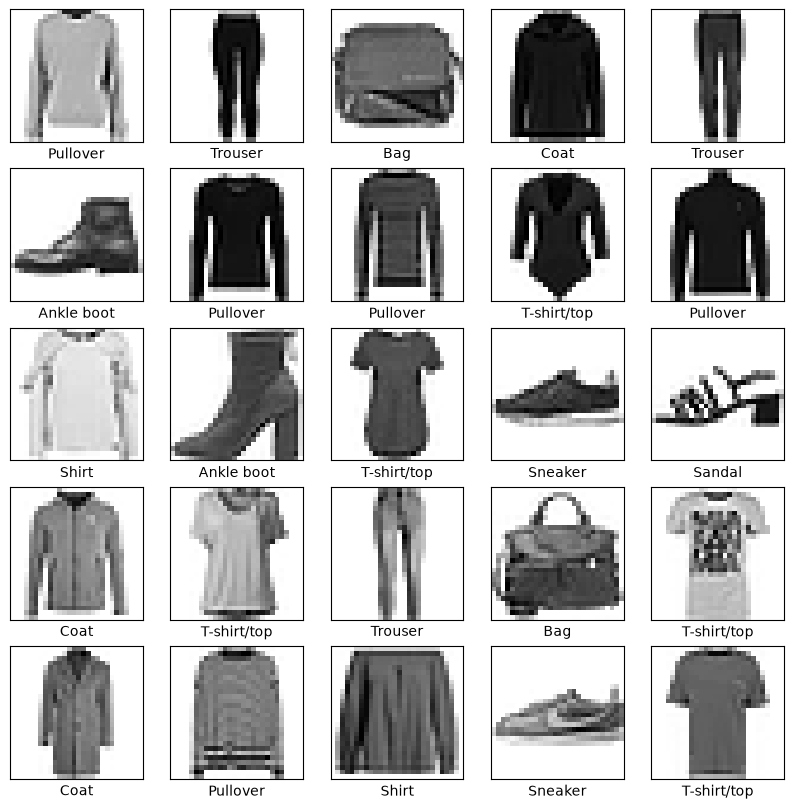

In [10]:
plt.figure(figsize=(10,10))
for i, (imagen, etiqueta) in enumerate(datos_entrenamiento.take(25)):
    imagen = imagen.numpy().reshape((28,28))
    plt.subplot(5,5,i+1)
    plt.xticks([])
    plt.yticks([])
    plt.imshow(imagen, cmap=plt.cm.binary)
    plt.xlabel(nombres_clases[etiqueta])
    plt.grid(True)
plt.show()

In [11]:
# Creación del modelo
modelo = tf.keras.Sequential([
    tf.keras.layers.Flatten(input_shape=(28,28,1)), # 1 - blanco y negro
    tf.keras.layers.Dense(50, activation=tf.nn.relu),
    tf.keras.layers.Dense(50, activation=tf.nn.relu),
    tf.keras.layers.Dense(10, activation=tf.nn.softmax) # Para redes de clasificación
])

/home/alexi-dg/anaconda3/lib/python3.14/site-packages/keras/src/layers/reshaping/flatten.py:37: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


In [12]:
# Compilar el modelo
modelo.compile(
    optimizer='adam',
    loss=tf.keras.losses.SparseCategoricalCrossentropy(),
    metrics=['accuracy']
)

In [13]:
num_ej_entrenamiento = metadatos.splits["train"].num_examples
num_ej_pruebas = metadatos.splits["test"].num_examples

In [14]:
print(num_ej_entrenamiento)
print(num_ej_pruebas)

60000
10000


In [15]:
TAMANO_LOTE = 32

datos_entrenamiento = datos_entrenamiento.repeat().shuffle(num_ej_entrenamiento).batch(TAMANO_LOTE)
datos_prueba = datos_prueba.batch(TAMANO_LOTE)

In [16]:
import math

# entrenar
historial = modelo.fit(datos_entrenamiento, epochs=5, steps_per_epoch=math.ceil(num_ej_entrenamiento/TAMANO_LOTE))

Epoch 1/5


/home/alexi-dg/anaconda3/lib/python3.14/site-packages/keras/src/trainers/epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


1875/1875 ━━━━━━━━━━━━━━━━━━━━ 3s 963us/step - accuracy: 0.8206 - loss: 0.5141
Epoch 2/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 2s 977us/step - accuracy: 0.8614 - loss: 0.3826
Epoch 3/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 2s 1ms/step - accuracy: 0.8722 - loss: 0.3544
Epoch 4/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 2s 978us/step - accuracy: 0.8787 - loss: 0.3276
Epoch 5/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 2s 973us/step - accuracy: 0.8842 - loss: 0.3115


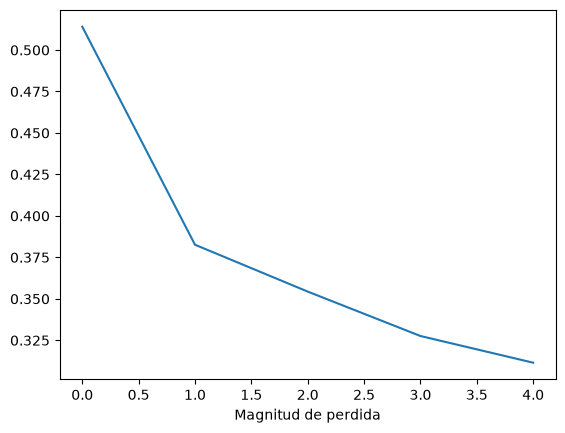

In [17]:
plt.xlabel("# Epoca")
plt.xlabel("Magnitud de perdida")
plt.plot(historial.history['loss'])

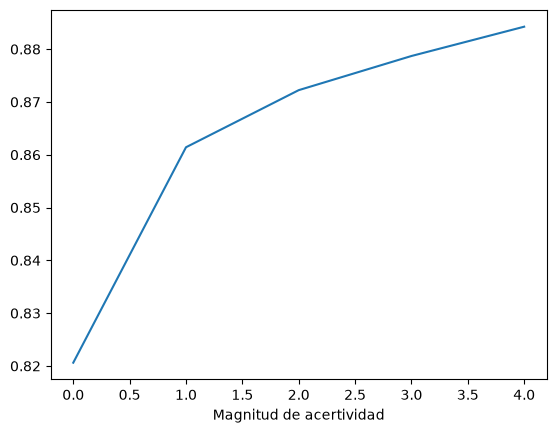

In [18]:
plt.xlabel("# Epoca")
plt.xlabel("Magnitud de acertividad")
plt.plot(historial.history['accuracy'])

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 25ms/step


W0000 00:00:1794280423.386138   58733 cache_dataset_ops.cc:956] The calling iterator did not fully read the dataset being cached. In order to avoid unexpected truncation of the dataset, the partially cached contents of the dataset will be discarded. This can happen if you have an input pipeline similar to `dataset.cache().take(k).repeat()`, or if downstream operations drop elements (e.g. `batch(drop_remainder=True)`). You should use `dataset.take(k).cache().repeat()` instead, or ensure the dataset size is a multiple of the batch size before caching. Another common workaround is to place the `.cache()` operation after the operation that drops elements (like `.batch(...)`), if caching the transformed data is acceptable.
W0000 00:00:1794280423.386213   58733 cache_dataset_ops.cc:956] The calling iterator did not fully read the dataset being cached. In order to avoid unexpected truncation of the dataset, the partially cached contents of the dataset will be discarded. This can happen if you

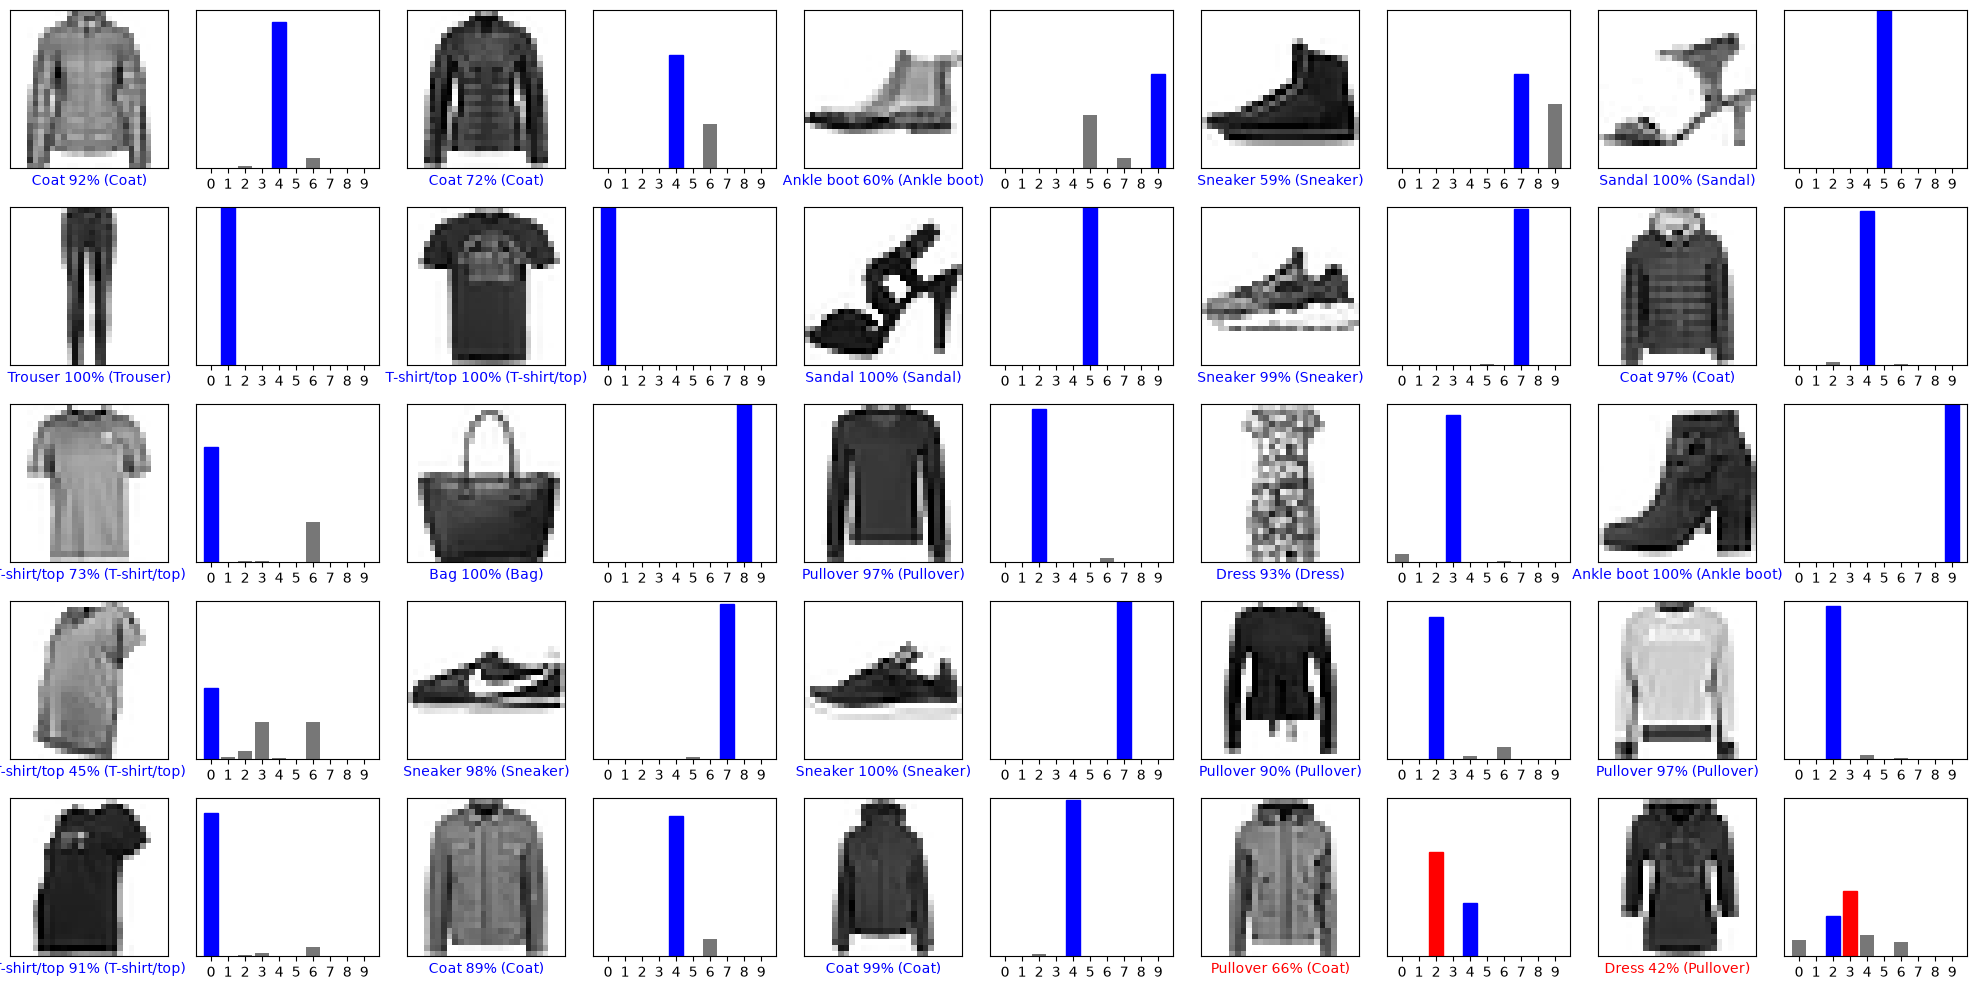

In [23]:
# Obtener un lote de imágenes de prueba
for imagenes_prueba, etiquetas_prueba in datos_prueba.take(1):
    imagenes_prueba = imagenes_prueba.numpy()
    etiquetas_prueba = etiquetas_prueba.numpy()

    predicciones = modelo.predict(imagenes_prueba)


# Visualizar una imagen y su predicción
def graficar_imagen(i, arr_predicciones, etiquetas_reales, imagenes):
    arr_predicciones = arr_predicciones[i]
    etiqueta_real = etiquetas_reales[i]
    img = imagenes[i]

    plt.grid(False)
    plt.xticks([])
    plt.yticks([])

    plt.imshow(img[..., 0], cmap=plt.cm.binary)

    etiqueta_prediccion = np.argmax(arr_predicciones)

    color = 'blue' if etiqueta_prediccion == etiqueta_real else 'red'

    plt.xlabel(
        "{} {:2.0f}% ({})".format(
            nombres_clases[etiqueta_prediccion],
            100 * np.max(arr_predicciones),
            nombres_clases[etiqueta_real]
        ),
        color=color
    )


# Visualizar las probabilidades de cada clase
def graficar_valor_arreglo(i, arr_predicciones, etiqueta_real):
    arr_predicciones = arr_predicciones[i]
    etiqueta_real = etiqueta_real[i]

    plt.grid(False)
    plt.xticks(range(10))
    plt.yticks([])

    grafica = plt.bar(
        range(10),
        arr_predicciones,
        color="#777777"
    )

    plt.ylim([0, 1])

    etiqueta_prediccion = np.argmax(arr_predicciones)

    grafica[etiqueta_prediccion].set_color('red')
    grafica[etiqueta_real].set_color('blue')


# Generar una cuadrícula de 25 predicciones
filas = 5
columnas = 5
num_imagenes = filas * columnas

plt.figure(figsize=(2 * 2 * columnas, 2 * filas))

for i in range(min(num_imagenes, len(imagenes_prueba))):

    plt.subplot(filas, 2 * columnas, 2 * i + 1)

    graficar_imagen(
        i,
        predicciones,
        etiquetas_prueba,
        imagenes_prueba
    )

    plt.subplot(filas, 2 * columnas, 2 * i + 2)

    graficar_valor_arreglo(
        i,
        predicciones,
        etiquetas_prueba
    )

plt.tight_layout()
plt.show()


In [24]:
# TOmar cualquier indice del set de pruebas para ver su predicción
imagen = imagenes_prueba[10]
imagen = np.array([imagen])
prediccion = modelo.predict(imagen)

print("Predicción: " + nombres_clases[np.argmax(prediccion[0])])

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 67ms/step
Predicción: T-shirt/top


In [25]:
# exportar modelo
modelo.save('modelo_exportado.h5')